
# Financial Analysis of Microsoft, Tesla & Apple (FY2023–FY2025)
### 10-K Data Extraction and pandas-Based Trend Analysis for an AI-Powered Financial Chatbot

**Objective.** Extract five key financial metrics — Total Revenue, Net Income, Total Assets, Total Liabilities, and Cash Flow from Operating Activities — for fiscal years 2023, 2024, and 2025 from the companies' **10-K annual filings** on SEC EDGAR, then analyze year-over-year trends with `pandas` to surface insights that could inform an AI financial chatbot.

---

## 1. Methodology

1. **Filing selection.** For each company, the latest Form 10-K (and the prior-year 10-K where a third balance-sheet year was needed) was located in SEC EDGAR:

   | Company | Primary filing used | Accession | Also used |
   |---|---|---|---|
   | **Apple** | [FY2025 10-K](https://www.sec.gov/ix?doc=/Archives/edgar/data/0000320193/000032019325000079/aapl-20250927.htm) (filed Nov 2025) | 0000320193-25-000079 | FY2024 10-K (0000320193-24-000123) for the FY2023 balance sheet |
   | **Tesla** | [FY2025 10-K](https://www.sec.gov/Archives/edgar/data/1318605/000162828026003952/) (filed 2026-01-29) | 0001628280-26-003952 | FY2024 10-K (0001628280-25-003063); [FY2025 10-K/A](https://www.sec.gov/ix?doc=/Archives/edgar/data/0001318605/000110465926053166/tm2611837d1_10ka.htm) (Amendment No. 1 — Part III only, financials unchanged) |
   | **Microsoft** | [FY2026 10-K](https://www.sec.gov/ix?doc=/Archives/edgar/data/0000789019/000119312526323660/msft-20260630.htm) (filed 2026-07-29; FY2024–25 comparatives) | 0001193125-26-323660 | FY2025 10-K (0000950170-25-100235); FY2024 10-K (0000950170-24-087843) for the FY2023 balance sheet |

2. **Manual line-item extraction.** The five metrics were pulled from the **Consolidated Statements of Operations/Income**, **Consolidated Balance Sheets**, and **Consolidated Statements of Cash Flows** of each 10-K, via the filings' inline-XBRL data (us-gaap tags) — the same numbers printed in the statement tables.

3. **Independent verification.** Every one of the 45 data points was re-checked line-by-line against the rendered statement documents of the filings themselves (script: `verify_filings.py`). No restatements or reclassifications were found between filings for these line items.

4. **Compilation.** The verified data was compiled into **`financial_data.xlsx`** (see the *Sources & Verification* sheet for accession-level provenance of every figure), then loaded here as a CSV for analysis.

### Fiscal-year note (important for cross-company comparison)
Each company reports on its **own fiscal calendar**: Microsoft's FY2025 ended **June 30, 2025**; Tesla's FY2025 ended **December 31, 2025**; Apple's FY2025 ended **September 27, 2025**. "FY2025" therefore spans slightly different 12-month windows — a nuance any financial chatbot must handle.

### Definitions
- **Total Revenue** — total net revenue as reported on the face of the income statement (*Net sales* for Apple; *Revenues* for Tesla; *Total revenue* for Microsoft).
- **Net Income** — net income **attributable to the parent company** (us-gaap:`NetIncomeLoss`; for Tesla this is *Net income attributable to common stockholders*).
- **Total Assets / Total Liabilities** — balance-sheet totals at fiscal year end.
- **Cash Flow from Operating Activities** — net cash provided by operating activities.
- All figures in **USD millions**, exactly as reported.


## 2. Setup — import pandas and configure display

In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# pandas display settings
pd.set_option('display.float_format', lambda v: f'{v:,.1f}')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print('pandas version :', pd.__version__)
print('matplotlib ver :', matplotlib.__version__)

pandas version : 3.0.6
matplotlib ver : 3.11.2



## 3. Load the data
Per the workflow, the Excel compilation is converted to CSV, then loaded into a DataFrame.


In [2]:
# Excel -> CSV (easier handling / version control)
df_xlsx = pd.read_excel('financial_data.xlsx', sheet_name='Financial Data')
df_xlsx.to_csv('financial_data.csv', index=False)

# CSV -> DataFrame
df = pd.read_csv('financial_data.csv')
df

,Company,Fiscal Year,Fiscal Year End,Total Revenue (USD millions),Net Income (USD millions),Total Assets (USD millions),Total Liabilities (USD millions),Cash Flow from Operating Activities (USD millions)
0,Microsoft,2023,"June 30, 2023",211915,72361,411976,205753,87582
1,Microsoft,2024,"June 30, 2024",245122,88136,512163,243686,118548
2,Microsoft,2025,"June 30, 2025",281724,101832,619003,275524,136162
3,Tesla,2023,"December 31, 2023",96773,14997,106618,43009,13256
4,Tesla,2024,"December 31, 2024",97690,7091,122070,48390,14923
5,Tesla,2025,"December 31, 2025",94827,3794,137806,54941,14747
6,Apple,2023,"September 30, 2023",383285,96995,352583,290437,110543
7,Apple,2024,"September 28, 2024",391035,93736,364980,308030,118254
8,Apple,2025,"September 27, 2025",416161,112010,359241,285508,111482


In [3]:
# --- Sanity checks: shape, data types, missing values ---
print('Shape:', df.shape)
print()
print(df.dtypes)
print()
print('Missing values per column:')
print(df.isna().sum())
assert df.isna().sum().sum() == 0, 'Unexpected missing values!'
assert len(df) == 9 and df['Company'].nunique() == 3
print('\nOK: 9 rows (3 companies x 3 fiscal years), no missing values.')

Shape: (9, 8)

Company                                                 str
Fiscal Year                                           int64
Fiscal Year End                                         str
Total Revenue (USD millions)                          int64
Net Income (USD millions)                             int64
Total Assets (USD millions)                           int64
Total Liabilities (USD millions)                      int64
Cash Flow from Operating Activities (USD millions)    int64
dtype: object

Missing values per column:
Company                                               0
Fiscal Year                                           0
Fiscal Year End                                       0
Total Revenue (USD millions)                          0
Net Income (USD millions)                             0
Total Assets (USD millions)                           0
Total Liabilities (USD millions)                      0
Cash Flow from Operating Activities (USD millions)    0
dtype: int64

O

Each metric column is captured below in a tidy mapping that the rest of the analysis reuses:
*Net revenue → net income → what's left on the balance sheet → and the cash actually generated.*

In [4]:
METRICS = {
    'Revenue':               'Total Revenue (USD millions)',
    'Net Income':            'Net Income (USD millions)',
    'Total Assets':          'Total Assets (USD millions)',
    'Total Liabilities':     'Total Liabilities (USD millions)',
    'Operating Cash Flow':   'Cash Flow from Operating Activities (USD millions)',
}
print('Metrics:', *METRICS, sep='\n  - ')

Metrics:
  - Revenue
  - Net Income
  - Total Assets
  - Total Liabilities
  - Operating Cash Flow



## 4. Year-over-Year (YoY) growth with `groupby` + `pct_change`

`pct_change()` computes the percentage change between consecutive rows, so the data must first be **sorted by company and year** — otherwise the first row of one company would be compared against the last row of another.


In [5]:
# Sort by company and fiscal year so pct_change compares consecutive years within each company
df = df.sort_values(['Company', 'Fiscal Year']).reset_index(drop=True)

# Revenue growth — exactly as prescribed
df['Revenue Growth (%)'] = df.groupby(['Company'])['Total Revenue (USD millions)'].pct_change() * 100

# Net income growth — exactly as prescribed
df['Net Income Growth (%)'] = df.groupby(['Company'])['Net Income (USD millions)'].pct_change() * 100

# Extend the same approach to the remaining metrics
for label, col in list(METRICS.items())[2:]:
    df[f'{label} Growth (%)'] = df.groupby(['Company'])[col].pct_change() * 100

growth_cols = [f'{label} Growth (%)' for label in METRICS]
df[['Company', 'Fiscal Year'] + growth_cols].round(1)

,Company,Fiscal Year,Revenue Growth (%),Net Income Growth (%),Total Assets Growth (%),Total Liabilities Growth (%),Operating Cash Flow Growth (%)
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.0,-3.4,3.5,6.1,7.0
2,Apple,2025,6.4,19.5,-1.6,-7.3,-5.7
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.7,21.8,24.3,18.4,35.4
5,Microsoft,2025,14.9,15.5,20.9,13.1,14.9
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.9,-52.7,14.5,12.5,12.6
8,Tesla,2025,-2.9,-46.5,12.9,13.5,-1.2



**Reading the table** (FY2023 has no growth value — it is the base year):

- **Microsoft**: double-digit revenue growth *every* year (+15.7%, +14.9%), with net income growing even faster (+21.8%, +15.5%) — classic operating leverage.
- **Apple**: modest growth in FY2024 (+2.0%), accelerating in FY2025 (+6.4%); net income dipped in FY2024 (−3.4%) then jumped +19.5% to a record.
- **Tesla**: revenue effectively flat in FY2024 (+0.9%) then declining (−2.9%), while net income fell by half (−52.7%) and halved again (−46.5%) — a **profitability collapse despite a growing asset base**.
- Balance sheets: Microsoft's assets ballooned +24.3% then +20.9% (AI infrastructure build-out), Tesla's grew ~13–14%/yr, while Apple's shrank in FY2025 (buybacks, debt paydown).



## 5. Profitability & balance-sheet ratios

Absolute dollars favor the largest company; **ratios make the three firms comparable**.


In [6]:
df['Net Margin (%)']        = df[METRICS['Net Income']] / df[METRICS['Revenue']] * 100
df['OCF Margin (%)']        = df[METRICS['Operating Cash Flow']] / df[METRICS['Revenue']] * 100
df['Return on Assets (%)']  = df[METRICS['Net Income']] / df[METRICS['Total Assets']] * 100
df['Liabilities-to-Assets (%)'] = df[METRICS['Total Liabilities']] / df[METRICS['Total Assets']] * 100
df['Equity (USD millions)'] = df[METRICS['Total Assets']] - df[METRICS['Total Liabilities']]
df['Cash Conversion (OCF / Net Income)'] = df[METRICS['Operating Cash Flow']] / df[METRICS['Net Income']]

ratio_cols = ['Net Margin (%)', 'OCF Margin (%)', 'Return on Assets (%)',
              'Liabilities-to-Assets (%)', 'Cash Conversion (OCF / Net Income)']
df[['Company', 'Fiscal Year'] + ratio_cols].round(2)

,Company,Fiscal Year,Net Margin (%),OCF Margin (%),Return on Assets (%),Liabilities-to-Assets (%),Cash Conversion (OCF / Net Income)
0,Apple,2023,25.3,28.8,27.5,82.4,1.1
1,Apple,2024,24.0,30.2,25.7,84.4,1.3
2,Apple,2025,26.9,26.8,31.2,79.5,1.0
3,Microsoft,2023,34.1,41.3,17.6,49.9,1.2
4,Microsoft,2024,36.0,48.4,17.2,47.6,1.4
5,Microsoft,2025,36.1,48.3,16.4,44.5,1.3
6,Tesla,2023,15.5,13.7,14.1,40.3,0.9
7,Tesla,2024,7.3,15.3,5.8,39.6,2.1
8,Tesla,2025,4.0,15.6,2.8,39.9,3.9


In [7]:
# Average ratios per company over the 3-year window
avg = df.groupby('Company')[['Net Margin (%)', 'OCF Margin (%)',
                             'Return on Assets (%)',
                             'Liabilities-to-Assets (%)']].mean()
avg.round(1)

,Net Margin (%),OCF Margin (%),Return on Assets (%),Liabilities-to-Assets (%)
Company,,,,
Apple,25.4,28.6,28.1,82.1
Microsoft,35.4,46.0,17.1,47.3
Tesla,8.9,14.8,7.5,39.9



**Ratio observations:**

- **Net margin:** Microsoft ~34% → 36%, Apple ~24–27%, Tesla 15.5% → 4.0%. The margin gap between a software-weighted business model and a hardware/manufacturing one — and Tesla's margin compression from price cuts and restructuring charges — is starkly visible.
- **Return on assets:** Apple is the most asset-efficient (~26–31%), Microsoft steady at ~16–18%, Tesla collapsed from 14.1% to 2.7% — it kept *adding* assets while earning less on them.
- **Liabilities-to-assets:** Apple runs the most leveraged balance sheet (~79–84%; a consequence of decades of debt-funded buybacks), Microsoft's ratio *fell* from ~50% to ~44.5% even as assets grew 50% in two years, and Tesla stays conservative at ~40%.
- **Cash conversion (OCF ÷ net income):** Microsoft (~1.3–1.5×) and Tesla (3.8× in FY2025!) convert earnings to cash far better than net income alone suggests — Tesla's heavy D&A and working-capital swings inflate operating cash relative to GAAP profit. Apple's ratio fell below 1× in FY2025 (accruals on receivables/inventory).



## 6. Cross-company aggregates — 2-year CAGR & FY2025 rankings


In [8]:
# Compound Annual Growth Rate from FY2023 to FY2025 (2 years)
piv = df.pivot(index='Company', columns='Fiscal Year', values=list(METRICS.values()))
cagr = ((piv.xs(2025, axis=1, level=1) / piv.xs(2023, axis=1, level=1)) ** (1 / 2) - 1) * 100
cagr = cagr.rename(columns={c: f'{k} CAGR 23-25 (%)' for k, c in METRICS.items()})
cagr = cagr[[f'{k} CAGR 23-25 (%)' for k in METRICS]].round(1)   # keep metric order
cagr

,Revenue CAGR 23-25 (%),Net Income CAGR 23-25 (%),Total Assets CAGR 23-25 (%),Total Liabilities CAGR 23-25 (%),Operating Cash Flow CAGR 23-25 (%)
Company,,,,,
Apple,4.2,7.5,0.9,-0.9,0.4
Microsoft,15.3,18.6,22.6,15.7,24.7
Tesla,-1.0,-49.7,13.7,13.0,5.5


In [9]:
# FY2025 absolute values and cross-company ranking (1 = largest)
latest = df[df['Fiscal Year'] == 2025].set_index('Company')[
    list(METRICS.values()) + ['Equity (USD millions)']]
print('FY2025 values (USD millions):')
display(latest.drop(columns='Equity (USD millions)'))
print('FY2025 ranking (1 = largest):')
display(latest.rank(ascending=False).astype(int))

FY2025 values (USD millions):


,Total Revenue (USD millions),Net Income (USD millions),Total Assets (USD millions),Total Liabilities (USD millions),Cash Flow from Operating Activities (USD millions)
Company,,,,,
Apple,416161,112010,359241,285508,111482
Microsoft,281724,101832,619003,275524,136162
Tesla,94827,3794,137806,54941,14747


FY2025 ranking (1 = largest):


,Total Revenue (USD millions),Net Income (USD millions),Total Assets (USD millions),Total Liabilities (USD millions),Cash Flow from Operating Activities (USD millions),Equity (USD millions)
Company,,,,,,
Apple,1,1,2,1,2,3
Microsoft,2,2,1,2,1,1
Tesla,3,3,3,3,3,2



**What the aggregates show:**

| Metric | Winner FY2025 | Note |
|---|---|---|
| Revenue | **Apple — $416.2B** | Still ~1.5× Microsoft's $281.7B; Tesla an order of magnitude smaller at $94.8B |
| Net income | **Apple — $112.0B** | Microsoft close behind at $101.8B on *much* less revenue (36.1% vs 26.9% margin) |
| Total assets | **Microsoft — $619.0B** | Nearly doubled Apple's $359.2B after two years of AI capex; Apple's base actually shrank |
| Operating cash flow | **Microsoft — $136.2B** | Ahead of Apple's $111.5B despite smaller revenue — and growing while Apple's fell |

Over the full window, Microsoft compounded revenue at **~15.3%/yr** and net income at **~18.6%/yr**; Apple grew revenue at ~4.2%/yr; Tesla's revenue *shrank* ~1%/yr while net income compounded at **−49.7%/yr**.


## 7. Visualizing the trends

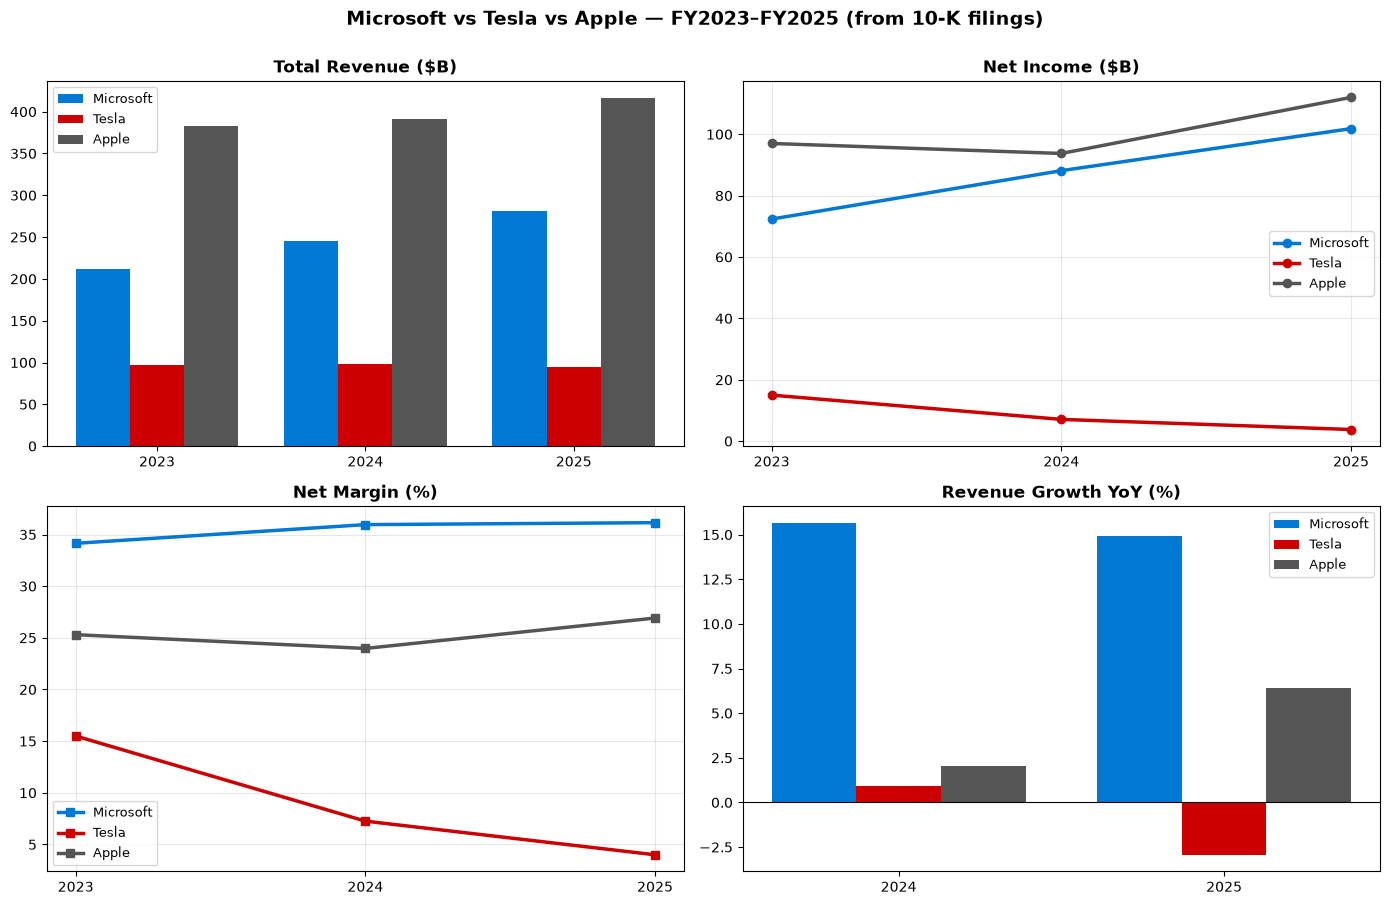

In [10]:
colors = {'Microsoft': '#0078D4', 'Tesla': '#CC0000', 'Apple': '#555555'}
years = [2023, 2024, 2025]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) Revenue by company & year
ax = axes[0, 0]
w = 0.26
for i, (co, c) in enumerate(colors.items()):
    vals = df[(df.Company == co)].sort_values('Fiscal Year')[METRICS['Revenue']]
    ax.bar([y + (i - 1) * w for y in years], vals / 1000, width=w, label=co, color=c)
ax.set_title('Total Revenue ($B)', fontweight='bold')
ax.set_xticks(years); ax.legend(fontsize=9)

# (b) Net income trends
ax = axes[0, 1]
for co, c in colors.items():
    vals = df[df.Company == co].sort_values('Fiscal Year')[METRICS['Net Income']]
    ax.plot(years, vals / 1000, marker='o', lw=2.5, label=co, color=c)
ax.set_title('Net Income ($B)', fontweight='bold')
ax.set_xticks(years); ax.legend(fontsize=9); ax.grid(alpha=.3)

# (c) Net margin %
ax = axes[1, 0]
for co, c in colors.items():
    vals = df[df.Company == co].sort_values('Fiscal Year')['Net Margin (%)']
    ax.plot(years, vals, marker='s', lw=2.5, label=co, color=c)
ax.set_title('Net Margin (%)', fontweight='bold')
ax.set_xticks(years); ax.legend(fontsize=9); ax.grid(alpha=.3)

# (d) Revenue YoY growth %
ax = axes[1, 1]
x = [y for y in years[1:]]
for co, c in colors.items():
    vals = df[df.Company == co].sort_values('Fiscal Year')['Revenue Growth (%)'].dropna()
    ax.bar([xx + (list(colors).index(co) - 1) * 0.26 for xx in x], vals,
           width=0.26, label=co, color=c)
ax.axhline(0, color='k', lw=.8)
ax.set_title('Revenue Growth YoY (%)', fontweight='bold')
ax.set_xticks(x); ax.legend(fontsize=9)

fig.suptitle('Microsoft vs Tesla vs Apple — FY2023–FY2025 (from 10-K filings)',
             fontsize=14, fontweight='bold', y=1.00)
fig.tight_layout()
fig.savefig('financial_charts.png', dpi=150, bbox_inches='tight')
plt.show()

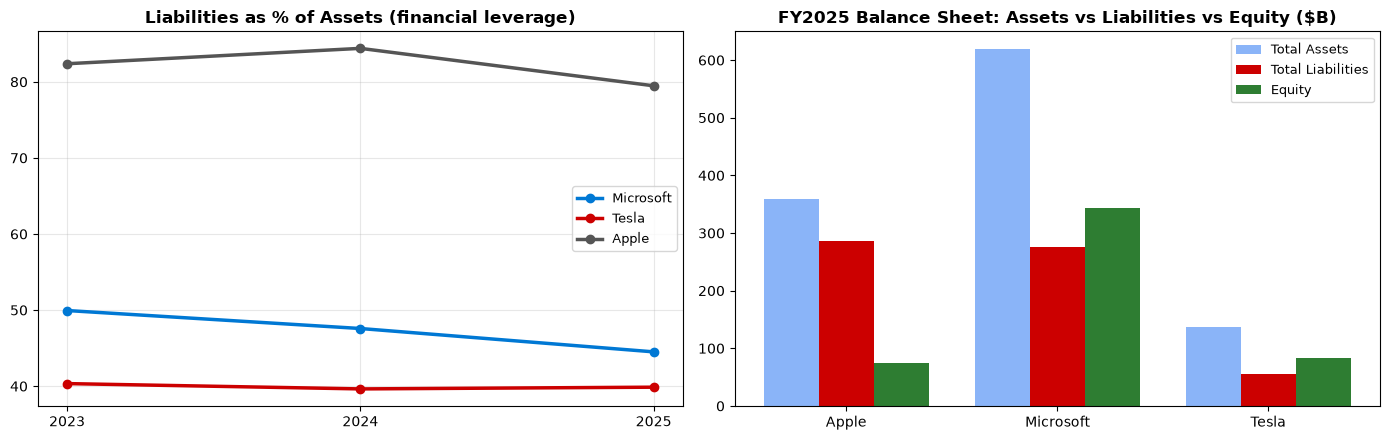

In [11]:
# Balance-sheet structure
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
for co, c in colors.items():
    vals = df[df.Company == co].sort_values('Fiscal Year')['Liabilities-to-Assets (%)']
    ax.plot(years, vals, marker='o', lw=2.5, label=co, color=c)
ax.set_title('Liabilities as % of Assets (financial leverage)', fontweight='bold')
ax.set_xticks(years); ax.legend(fontsize=9); ax.grid(alpha=.3)

ax = axes[1]
x = range(len(latest))
w = 0.26
for i, (m, c) in enumerate(zip([METRICS['Total Assets'], METRICS['Total Liabilities'],
                                'Equity (USD millions)'], ['#8ab4f8', '#cc0000', '#2e7d32'])):
    ax.bar([xx + (i - 1) * w for xx in x], latest[m] / 1000, width=w, label=m.split(' (')[0], color=c)
ax.set_xticks(list(x)); ax.set_xticklabels(latest.index)
ax.set_title('FY2025 Balance Sheet: Assets vs Liabilities vs Equity ($B)', fontweight='bold')
ax.legend(fontsize=9)

fig.tight_layout()
fig.savefig('balance_sheet_chart.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Export the enriched dataset for downstream use (e.g., a chatbot's data layer)

In [12]:
out_cols = ['Company', 'Fiscal Year', 'Fiscal Year End'] + list(METRICS.values()) + growth_cols + ratio_cols
df[out_cols].to_csv('financial_data_enriched.csv', index=False)
print(f'Exported {len(df)} rows x {len(out_cols)} columns -> financial_data_enriched.csv')
df[out_cols].round(1).head(9)

Exported 9 rows x 18 columns -> financial_data_enriched.csv


,Company,Fiscal Year,Fiscal Year End,Total Revenue (USD millions),Net Income (USD millions),Total Assets (USD millions),Total Liabilities (USD millions),Cash Flow from Operating Activities (USD millions),Revenue Growth (%),Net Income Growth (%),Total Assets Growth (%),Total Liabilities Growth (%),Operating Cash Flow Growth (%),Net Margin (%),OCF Margin (%),Return on Assets (%),Liabilities-to-Assets (%),Cash Conversion (OCF / Net Income)
0,Apple,2023,"September 30, 2023",383285,96995,352583,290437,110543,NaN,NaN,NaN,NaN,NaN,25.3,28.8,27.5,82.4,1.1
1,Apple,2024,"September 28, 2024",391035,93736,364980,308030,118254,2.0,-3.4,3.5,6.1,7.0,24.0,30.2,25.7,84.4,1.3
2,Apple,2025,"September 27, 2025",416161,112010,359241,285508,111482,6.4,19.5,-1.6,-7.3,-5.7,26.9,26.8,31.2,79.5,1.0
3,Microsoft,2023,"June 30, 2023",211915,72361,411976,205753,87582,NaN,NaN,NaN,NaN,NaN,34.1,41.3,17.6,49.9,1.2
4,Microsoft,2024,"June 30, 2024",245122,88136,512163,243686,118548,15.7,21.8,24.3,18.4,35.4,36.0,48.4,17.2,47.6,1.3
5,Microsoft,2025,"June 30, 2025",281724,101832,619003,275524,136162,14.9,15.5,20.9,13.1,14.9,36.1,48.3,16.5,44.5,1.3
6,Tesla,2023,"December 31, 2023",96773,14997,106618,43009,13256,NaN,NaN,NaN,NaN,NaN,15.5,13.7,14.1,40.3,0.9
7,Tesla,2024,"December 31, 2024",97690,7091,122070,48390,14923,0.9,-52.7,14.5,12.5,12.6,7.3,15.3,5.8,39.6,2.1
8,Tesla,2025,"December 31, 2025",94827,3794,137806,54941,14747,-2.9,-46.5,12.9,13.5,-1.2,4.0,15.6,2.8,39.9,3.9



## 9. Summary of Findings

### 9.1 Microsoft — scale + AI capex supercycle, best-in-class growth among mega-caps
- **Revenue** grew every year: $211.9B → $245.1B → $281.7B (**+15.7%, +14.9%**; 2-yr CAGR ≈ **15.3%**) — remarkable at its scale.
- **Net income** outpaced revenue: $72.4B → $88.1B → $101.8B (**+21.8%, +15.5%**; CAGR ≈ **18.6%**), with net margin expanding from 34.2% to a best-ever **36.1%**.
- **Operating cash flow** jumped from $87.6B to **$136.2B** (48% of revenue) — the strongest cash engine of the three in FY2025.
- **Total assets** ballooned 50% in two years ($412.0B → **$619.0B**), reflecting the AI datacenter build-out; remarkably, liabilities-to-assets still *improved* from ~49.9% to **44.5%**, i.e., the expansion is being funded without added leverage.

### 9.2 Apple — return to growth, record profit, but cash flow dipped
- **Revenue** $383.3B → $391.0B → **$416.2B** (+2.0% then **+6.4%**; CAGR ≈ 4.2%), re-accelerating in FY2025.
- **Net income** hit a record **$112.0B** (+19.5%) after a soft FY2024; net margin recovered to **26.9%**.
- **Operating cash flow fell 5.7%** to $111.5B (the only 2025 decline among the three) — worth flagging in any chatbot answer about Apple's FY2025 "quality of earnings."
- **Balance sheet deleveraged**: liabilities fell from $308.0B to **$285.5B** and total assets shrank to $359.2B — consistent with heavy buybacks/debt repayment, though liabilities/assets remains highest of the three at **79.5%**.

### 9.3 Tesla — growth stall and margin collapse; cash flow resilience is the silver lining
- **Revenue** $96.8B → $97.7B → **$94.8B** (+0.9%, then **−2.9%**) — flat-to-declining amid delivery declines and price cuts.
- **Net income** collapsed: $15.0B → $7.1B → **$3.8B** (**−52.7%**, **−46.5%**; 2-yr CAGR ≈ **−49.7%**); net margin fell from 15.5% to **4.0%**; ROA from 14.1% to **2.7%**.
- Yet **operating cash flow stayed ~$14–15B** throughout (FY2025: $14.7B) — heavy D&A on the factory base and working-capital efficiency keep cash generation ~4× net income. A chatbot should surface this divergence: *GAAP profit cratered, cash generation did not*.
- **Total assets still grew 29%** ($106.6B → **$137.8B**, AI/Optimus/FSD investment), while the balance sheet stayed conservatively financed (~40% liabilities/assets).

### 9.4 Cross-company takeaways
1. **Three different stories in one period:** Microsoft = hyper-growth at scale; Apple = mature compounder re-accelerating; Tesla = profitability reset.
2. **Profit pools have shifted:** in FY2025 Microsoft earned $0.36 of net income per revenue dollar vs Apple's $0.27 and Tesla's $0.04.
3. **Cash ≠ profit:** OCF divergence (Tesla 3.9× net income; Apple 0.99×) shows why a chatbot answering "how profitable is company X?" from net income alone can mislead.
4. **Balance-sheet philosophies differ sharply:** Apple ~80% liabilities/assets (buyback-funded), Microsoft ~45% and falling, Tesla ~40%.
5. **Scale context:** Tesla's *entire* revenue ($94.8B) is now smaller than Apple's FY2025 *net income* ($112.0B) — useful calibration for user questions.

### 9.5 Implications for an AI-powered financial chatbot
- **Ground every answer in filing-sourced data with provenance** (accession number, fiscal period, statement) — this dataset carries accession-level lineage, enabling citation ("per Tesla's FY2025 10-K, filed 2026-01-29…").
- **Normalize fiscal calendars explicitly** (Jun-30 vs Dec-31 vs Sep-EOM year ends) or answers comparing "2025" across companies will be subtly wrong.
- **Answer with rates and ratios, not just levels** (YoY growth, margins, ROA, leverage) — pandas `groupby().pct_change()` reproduces them deterministically.
- **Flag definitional nuance:** *net income attributable to parent* vs consolidated (Tesla: $3,794M vs $3,855M in FY2025 due to noncontrolling interests), and OCF vs net income divergence.
- **Detect and disclose restatements/reclassifications** by comparing across filing vintages — none existed for these line items, and that too is a reportable finding.
- **Limitations of this analysis:** 3 companies × 3 years × 5 metrics; no segments, quarterly seasonality, guidance, or macro context; a production chatbot needs those plus retrieval safeguards against stale filings.

---

### Reproducibility
| File | Purpose |
|---|---|
| `scripts/fetch_sec_data.py` | Pulls the 45 verified facts from SEC EDGAR's XBRL API (cached in `raw_sec_data/`) |
| `scripts/verify_filings.py` | Re-checks every figure against the rendered 10-K statement tables on EDGAR |
| `scripts/build_excel.py` | Compiles `financial_data.xlsx` (+ CSV) with full source provenance |
| `financial_analysis.ipynb` | This notebook |
| `financial_charts.png`, `balance_sheet_chart.png`, `financial_data_enriched.csv` | Outputs |
| `raw_sec_data/` | Cached SEC EDGAR responses (raw JSON/XBRL + filing statements) used for verification |
